# The Simplest Forecast — Can Your Method Beat a Guess Anyone Can Make?

The same code as the second half (practice part) of the video.

- **Nothing to set up** (free, no install. You just need to be signed in to a Google account)
- **How to run**: press ▶ on each cell, from the top down (or Shift + Enter). The first time, if you see “This notebook was not authored by Google”, click “Run anyway”
- **To try your own changes**: first use “File → Save a copy in Drive” so you keep your own copy

*Original code: [marcopeix/TimeSeriesForecastingInPython](https://github.com/marcopeix/TimeSeriesForecastingInPython) (Apache License 2.0), modified by Mirai Graph.*

Today's words:
- 🔰 **Baseline** = a simple forecast we compare against
- 🔰 **Training set** = the past we may learn from
- 🔰 **Test set** = the answers we hide until the end

## 1. Load the tools and the data

In the video, the file path is shown as `../data/jj.csv` (a file inside the book's repository). This notebook loads the same file from a GitHub URL, so it runs in Colab on its own. The data is the same.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/marcopeix/TimeSeriesForecastingInPython/master/data/jj.csv')

## 2. Split into a training set and a test set

Only `test` gets `.copy()`, which makes it a separate table. That is because we add the forecast columns only to `test` (`train` is only read, so it does not need it). This also avoids a warning in older versions of pandas.

In [2]:
train = df.iloc[:-4]
test = df.iloc[-4:].copy()
len(train), len(test)

(80, 4)

## 3. Forecast 1: the last value

In [3]:
test['pred_last'] = train['data'].iloc[-1]

## 4. Forecast 2: last year's average

In [4]:
test['pred_last_yr_mean'] = train['data'].iloc[-4:].mean()

## 5. Forecast 3: the overall average

In [5]:
test['pred_mean'] = train['data'].mean()
test

,date,data,pred_last,pred_last_yr_mean,pred_mean
80,1980-01-01,16.20,9.99,12.96,4.3085
81,1980-04-01,14.67,9.99,12.96,4.3085
82,1980-07-02,16.02,9.99,12.96,4.3085
83,1980-10-01,11.61,9.99,12.96,4.3085


## 6. Compare on a chart

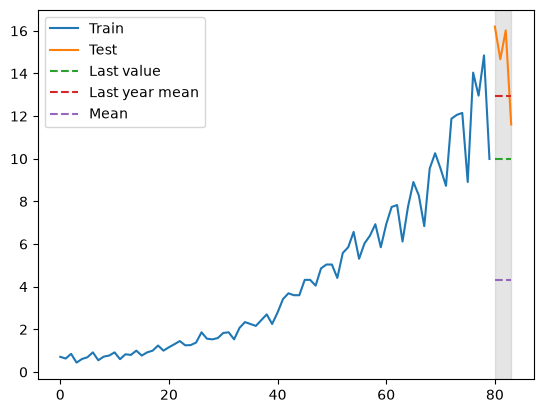

In [6]:
plt.plot(train['data'], label='Train')
plt.plot(test['data'], label='Test')
plt.plot(test['pred_last'], '--', label='Last value')
plt.plot(test['pred_last_yr_mean'], '--', label='Last year mean')
plt.plot(test['pred_mean'], '--', label='Mean')
plt.axvspan(80, 83, color='gray', alpha=0.2)
plt.legend();

## Try it

Note: after you edit a cell and press ▶, also run the cells below it (the table and the chart) to see the new results.

- How much of the past to use: in Forecast 2, change the -4 in `iloc[-4:]` to -8 to get a two-year average (12.105; the one-year average is 12.96). We used more data, yet it moves further from the answers. When the data keeps rising, newer data matters more.
- How far ahead to predict: in the split cell, change -4 to -8 in both places, and in the chart change the 80 in `axvspan(80, 83, ...)` to 76. If you predict two years ahead, the last value drops from 9.99 to 8.91 and last year's average from 12.96 to 11.25. The answers (the 8 values in 1979–1980) keep rising, so the forecasts end up a little further away. The further ahead, the harder it is to predict.

---
Code: adapted by Mirai Graph (2026) from [marcopeix/TimeSeriesForecastingInPython](https://github.com/marcopeix/TimeSeriesForecastingInPython) by the book's author, Marco Peixeiro. License: [Apache License 2.0](https://www.apache.org/licenses/LICENSE-2.0)

Data and credit: Johnson & Johnson quarterly earnings per share, 1960–1980 (Shumway & Stoffer, Time Series Analysis and Its Applications, Springer / R datasets: JohnsonJohnson; taken from data/jj.csv in the book's repository).